In [2]:
import pandas as pd

# Load the latest version
df = pd.read_csv("F:/Descargas/amz_uk_price_prediction_dataset.csv")
print("First 5 records:", df.head())


First 5 records:    uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [3]:
print(df.columns)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


# Part 1: Analyzing Best-Seller Trends Across Product Categories

In [4]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
print(crosstab)

isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [5]:
summary = crosstab.copy()
summary['total_products'] = summary.sum(axis=1)
summary['best_seller_ratio'] = summary[True] / summary['total_products']
summary = summary.sort_values('best_seller_ratio', ascending=False)
summary = summary.round(4)*100  # Convert to percentage
print(summary.head(10))

isBestSeller                     False   True  total_products  \
category                                                        
Grocery                         900800  55600          956400   
Smart Home Security & Lighting    9800    600           10400   
Health & Personal Care          901700  55200          956900   
Mobile Phone Accessories         24800   1100           25900   
Power & Hand Tools              835300  30600          865900   
Billiard, Snooker & Pool         24100    800           24900   
Pet Supplies                    915200  28500          943700   
Home Brewing & Wine Making       23900    700           24600   
Wind Instruments                 24300    700           25000   
Mirrors                          24300    700           25000   

isBestSeller                    best_seller_ratio  
category                                           
Grocery                                      5.81  
Smart Home Security & Lighting               5.77  
Health & Pe

In [6]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(crosstab)

print("=== Chi-Square Test Results ===")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom:   {dof}")
print(f"P-value:             {p:.4f}")

alpha = 0.05  # 95% confidence

if p < alpha:
    print("🚨 Reject H₀: The distribution of best-sellers **depends** on the product category.")
else:
    print("✅ Fail to reject H₀: The distribution of best-sellers is **independent** of product category.")


=== Chi-Square Test Results ===
Chi-square statistic: 36540.2027
Degrees of freedom:   295
P-value:             0.0000
🚨 Reject H₀: The distribution of best-sellers **depends** on the product category.


In [7]:
import numpy as np
# Cramér's V calculation
n = crosstab.sum().sum()  # Total observations
r, k = crosstab.shape     # Rows & columns
cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))

print("=== Association Strength ===")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p:.4f}")
print(f"Cramér's V: {cramers_v:.4f}")

if cramers_v < 0.10:
    strength = "Very weak / negligible"
elif cramers_v < 0.30:
    strength = "Weak"
elif cramers_v < 0.50:
    strength = "Moderate"
else:
    strength = "Strong"

print(f"Strength of association: {strength}")

=== Association Strength ===
Chi-square statistic: 36540.2027
P-value: 0.0000
Cramér's V: 0.1223
Strength of association: Weak


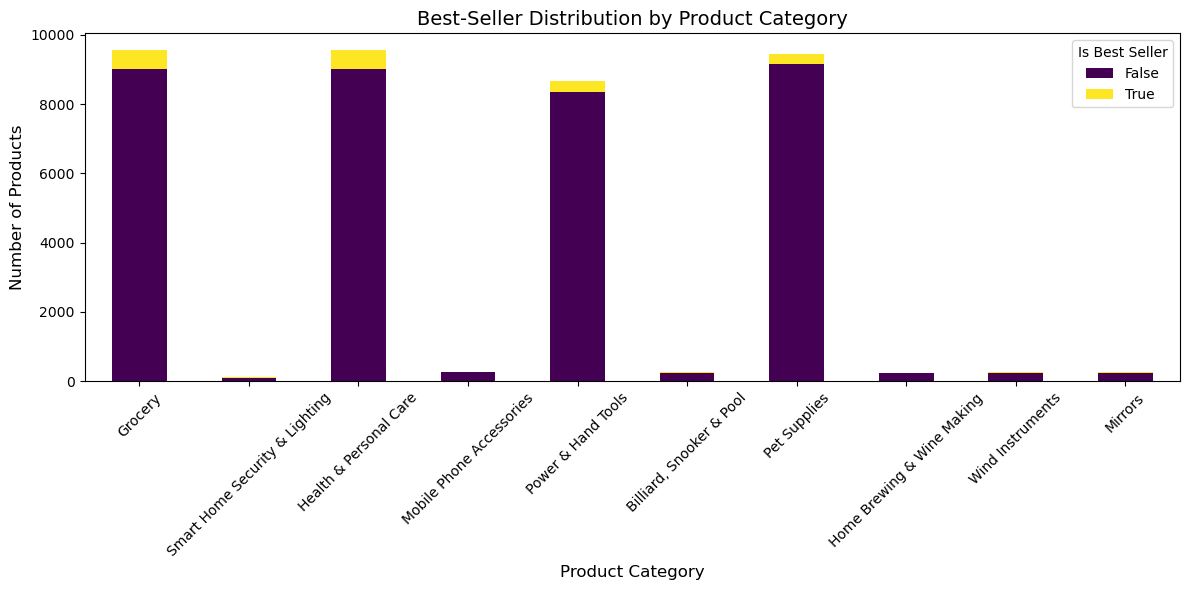

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

crosstab_sorted = crosstab.loc[summary.index]
crosstab_sorted.head(10).plot(kind="bar", stacked=True, figsize=(12,6), colormap="viridis")

plt.title("Best-Seller Distribution by Product Category", fontsize=14)
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Number of Products", fontsize=12)
plt.legend(title="Is Best Seller")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [9]:
# Calculate Q1, Q3, and IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

 # Filter the DataFrame to exclude outliers
df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

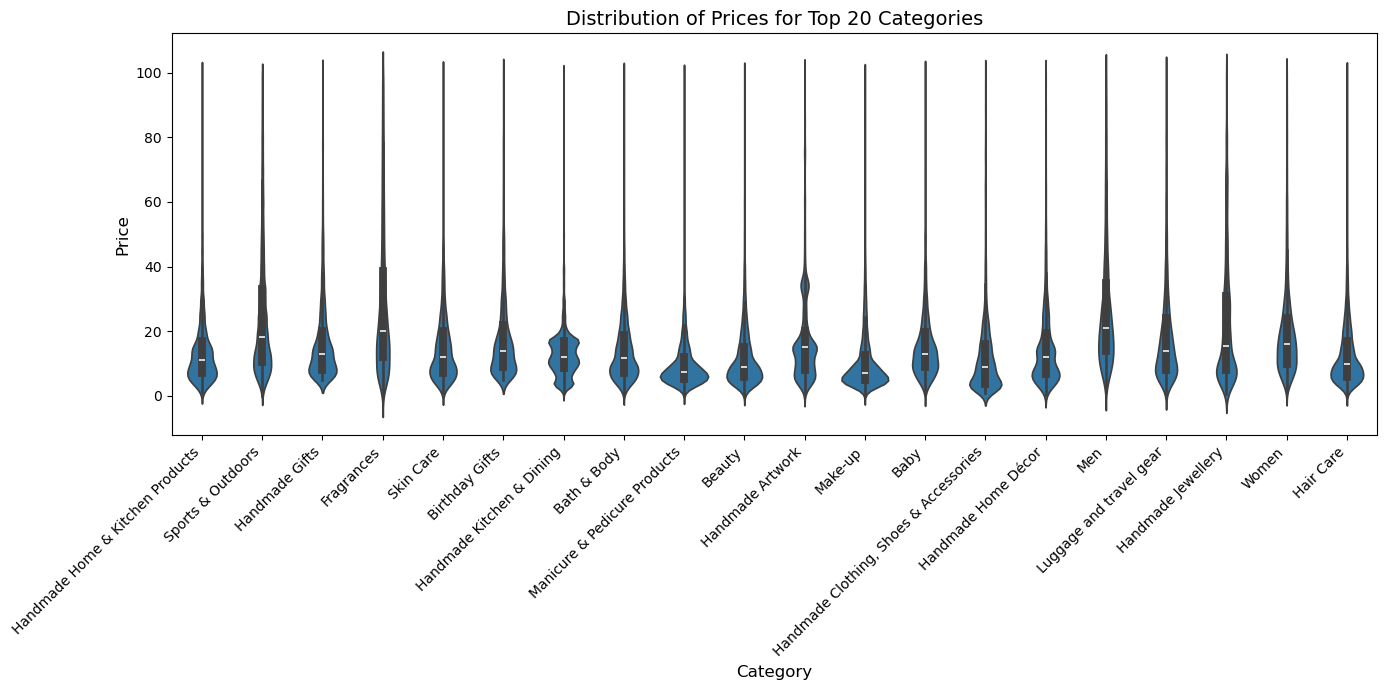

In [10]:
# Get top 20 product categories based on number of products
top_20_categories = df_clean['category'].value_counts().head(20).index

# Filter dataset
df_top20 = df_clean[df_clean['category'].isin(top_20_categories)]

plt.figure(figsize=(14, 7))
sns.violinplot(
    data=df_top20,
    x='category',
    y='price',
)

plt.title("Distribution of Prices for Top 20 Categories", fontsize=14)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

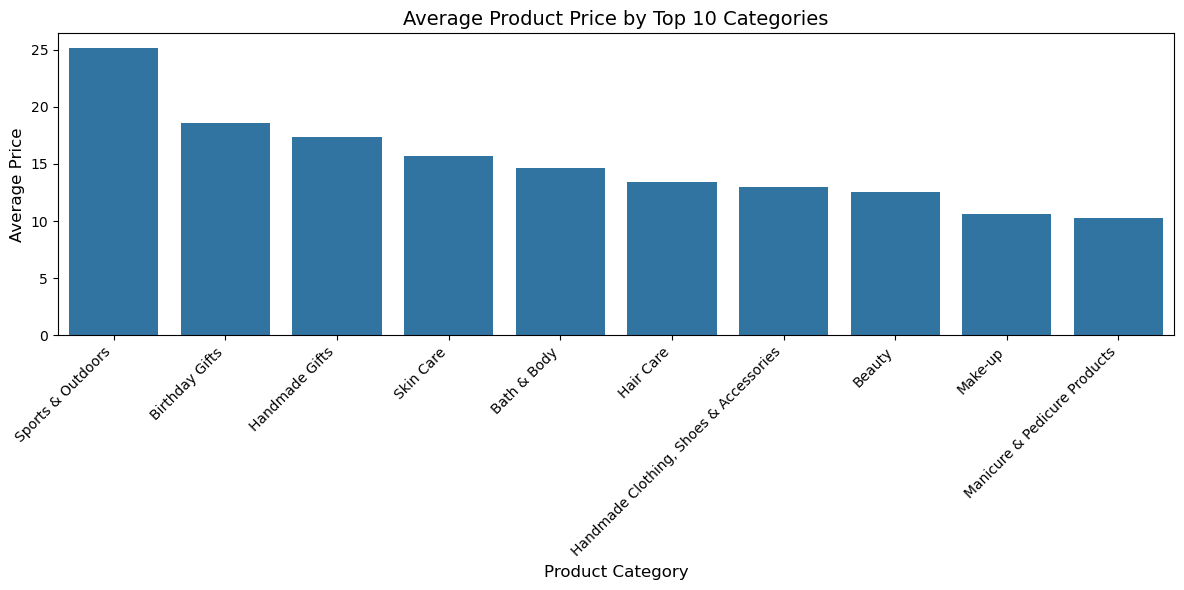

In [11]:
# Get the top 10 categories by number of products
top_10_categories = df_clean['category'].value_counts().head(10).index

# Filter dataset for top 10 categories only
df_top10 = df_clean[df_clean['category'].isin(top_10_categories)]

# Group by category and calculate mean price
avg_prices = (
    df_top10.groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

# Plotting
plt.figure(figsize=(12,6))
sns.barplot(
    x=avg_prices.index,
    y=avg_prices.values,
)

plt.title("Average Product Price by Top 10 Categories", fontsize=14)
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Average Price", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

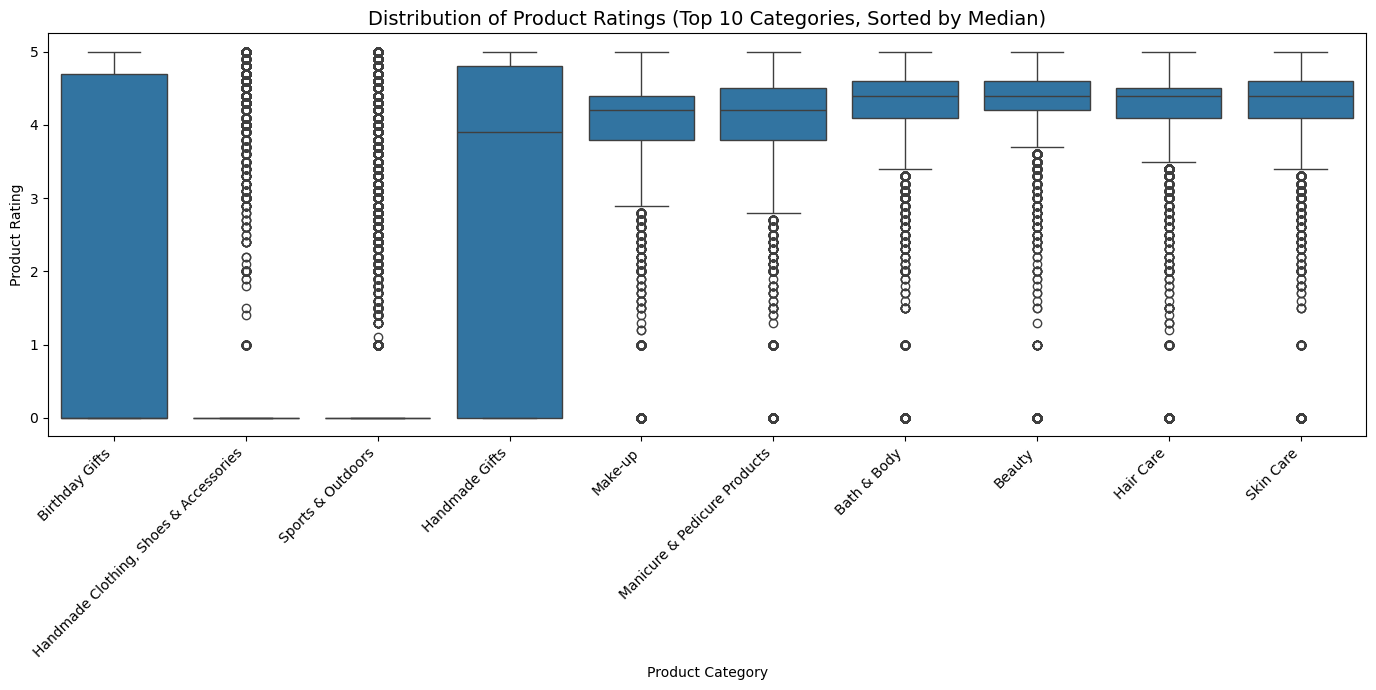

In [12]:
# Bloxkplot for ratings distribution across top 10 categories

# Get the rating distribution across top 10 categories
 
   
sorted_categories = (
    df_top10.groupby('category')['stars']
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(14, 7))
sns.boxplot(
    data=df_top10,
    x='category',
    y='stars',
    order=sorted_categories,
)

plt.title("Distribution of Product Ratings (Top 10 Categories, Sorted by Median)", fontsize=14)
plt.xlabel("Product Category")
plt.ylabel("Product Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Part 3: Investigating the Interplay Between Product Prices and Ratings


In [13]:
from scipy.stats import pearsonr
# Calculate the correlation coefficient between price and stars.
corr_coef, p_value = pearsonr(df_clean['price'], df_clean['stars'])

print("=== Correlation Analysis Between Price and Ratings ===")
print(f"Pearson correlation coefficient: {corr_coef:.4f}")
if abs(corr_coef) < 0.1:
    interpretation = "Very weak / negligible"
elif abs(corr_coef) < 0.3:
    interpretation = "Weak"
elif abs(corr_coef) < 0.5:
    interpretation = "Moderate" 
else:
    interpretation = "Strong"   
print(f"Interpretation: {interpretation}")
  

    


=== Correlation Analysis Between Price and Ratings ===
Pearson correlation coefficient: -0.0777
Interpretation: Very weak / negligible


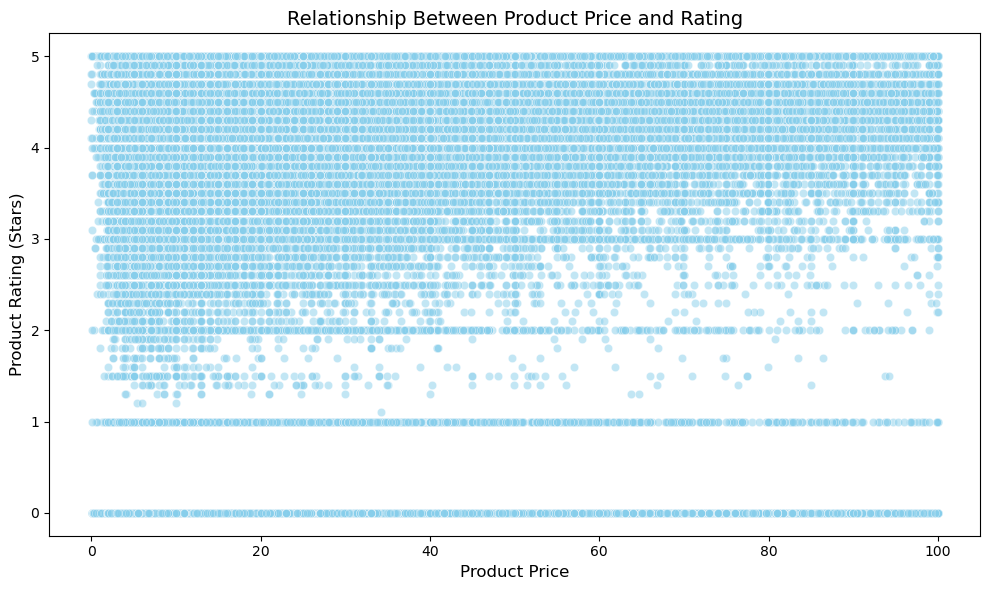

In [14]:

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df_top10,
    x='price',
    y='stars',
    alpha=0.5,
    color='skyblue'
)

plt.title("Relationship Between Product Price and Rating", fontsize=14)
plt.xlabel("Product Price", fontsize=12)
plt.ylabel("Product Rating (Stars)", fontsize=12)
plt.tight_layout()
plt.show()

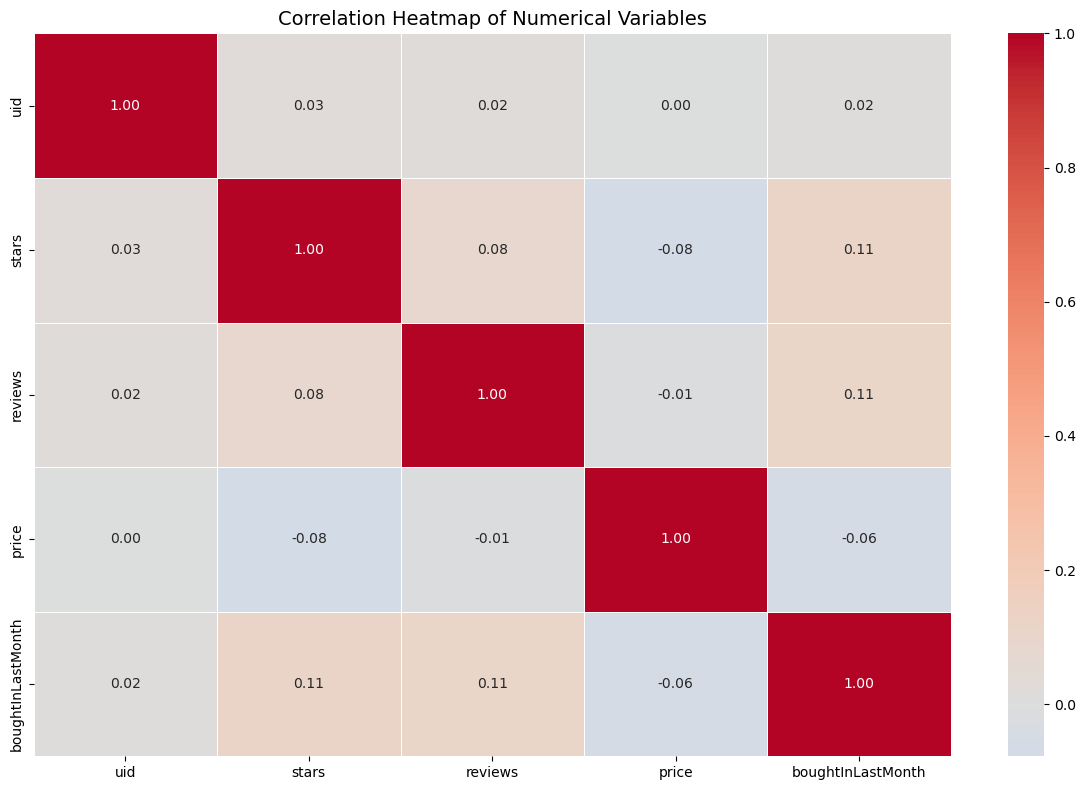

In [ ]:
# Select numerical columns
df_num = df_clean.select_dtypes(include=['float64', 'int64'])
# Compute correlation matrix
corr_matrix = df_num.corr()
# Set up the matplotlib figure
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,          # Show correlation values
    fmt=".2f",           # Two decimals
    cmap="coolwarm",     # Diverging color map
    center=0,            # Zero correlation = white
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables", fontsize=14)
plt.tight_layout()
plt.show()




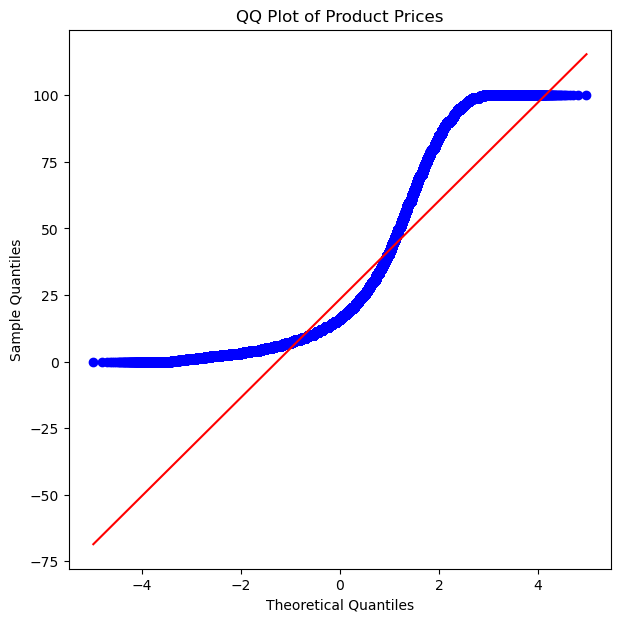

The QQ plot indicates that product prices deviate from a normal distribution, especially in the tails, suggesting a right-skewed distribution.


In [19]:
import scipy.stats as stats

plt.figure(figsize=(7, 7))
stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()

print("The QQ plot indicates that product prices deviate from a normal distribution, especially in the tails, suggesting a right-skewed distribution.")